# 02 - Exploratory Data Analysis (EDA)

Used car price prediction, step 2 of the project. Each step of the project has its own notebook:

- 01 - data loading, exploration, cleaning, and preprocessing
- **02 - exploratory data analysis (this notebook)**

This notebook starts from the cleaned file saved by notebook 01 (`data/processed/cardekho_cleaned.csv`).

**EDA uses the training data only.** We split the data the same way as in notebook 01 (80% training, 20% testing, `random_state=42`) and explore only the training part. The test set stays completely unseen, so nothing we notice here can quietly influence later choices about features or models.

All charts are saved as image files, so they can be reused in the README and the project documentation.

## 1. Setup

In [1]:
# Import the libraries used in this notebook
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

# A clean, light chart style, and a readable default chart size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Folder where the charts will be saved
os.makedirs("figures", exist_ok=True)

# Print the library versions (we pin them in requirements.txt later)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1


In [2]:
# A small helper: tidy the layout, save the chart as a PNG file, then show it
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the cleaned data

In [3]:
# Load the cleaned data that notebook 01 saved.
# First try to read it straight from the GitHub repo. If the repo is private, or the file
# has not been pushed yet, fall back to uploading the file by hand (a file picker appears).
DATA_URL = "https://raw.githubusercontent.com/MirajAdhikari/used-car-price-prediction/main/data/processed/cardekho_cleaned.csv"

try:
    clean = pd.read_csv(DATA_URL)
    print("Loaded the cleaned data from GitHub.")
except Exception:
    from google.colab import files
    uploaded = files.upload()                       # choose cardekho_cleaned.csv
    clean = pd.read_csv(next(iter(uploaded)))
    print("Loaded the cleaned data from the uploaded file.")

print("Shape (rows, columns):", clean.shape)


Loaded the cleaned data from GitHub.
Shape (rows, columns): (15240, 13)


## 3. Recreate the training set

We use exactly the same feature lists and the same split settings as in notebook 01, so the training set is identical.

In [4]:
# The same feature lists as in notebook 01
target = "selling_price"
numeric_features = ["vehicle_age", "km_driven", "mileage", "engine",
                    "max_power", "seats", "km_per_year"]
categorical_features = ["brand", "model", "seller_type", "fuel_type", "transmission_type"]

X = clean[numeric_features + categorical_features]
y = clean[target]

# The same 80/20 split as in notebook 01 (random_state=42 gives the same rows every time)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Test rows (not used here):", len(X_test))

# Build one table for EDA: training features + price
train = X_train.copy()
train["selling_price"] = y_train

# Prices are easier to read in lakh rupees (1 lakh = 100,000 rupees), the usual unit in India
train["price_lakh"] = train["selling_price"] / 100_000

# Log of the price. We will compare raw price and log price when modeling (Part 5).
train["log_price"] = np.log(train["selling_price"])

train.head()

Training rows: 12192 | Test rows (not used here): 3048


,vehicle_age,km_driven,mileage,engine,max_power,seats,km_per_year,brand,model,seller_type,fuel_type,transmission_type,selling_price,price_lakh,log_price
13567,4,35000,24.70,796,47.30,5,8750.000000,Maruti,Alto,Individual,Petrol,Manual,240000,2.4,12.388394
4745,13,185000,12.80,2494,102.00,7,14230.769231,Toyota,Innova,Dealer,Diesel,Manual,710000,7.1,13.473020
214,8,62000,22.70,1498,89.84,5,7750.000000,Ford,Ecosport,Dealer,Diesel,Manual,470000,4.7,13.060488
14340,4,23000,18.53,1968,187.74,5,5750.000000,Audi,A6,Dealer,Diesel,Automatic,3150000,31.5,14.962913
13299,4,40000,17.80,1198,86.70,5,10000.000000,Honda,Amaze,Individual,Petrol,Manual,500000,5.0,13.122363


In [5]:
# Summary statistics of the training data
train[numeric_features + ["price_lakh"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
vehicle_age,12192.0,6.03,3.02,0.0,4.00,6.00,8.00,29.00
km_driven,12192.0,55421.67,40895.94,100.0,30000.00,50000.00,70250.50,950000.00
mileage,12192.0,19.68,4.16,6.0,17.00,19.67,22.69,33.54
engine,12192.0,1486.63,520.37,793.0,1197.00,1248.00,1582.00,5998.00
max_power,12192.0,100.71,42.86,38.4,74.00,88.50,117.30,626.00
seats,12192.0,5.33,0.81,2.0,5.00,5.00,5.00,9.00
km_per_year,12192.0,9827.48,7501.92,100.0,5833.33,8461.54,12200.00,295000.00
price_lakh,12192.0,7.74,8.23,0.4,3.85,5.60,8.25,145.00


## 4. Price distribution

The target we predict is the selling price. First we check how it is distributed, and whether taking the log makes it more regular.

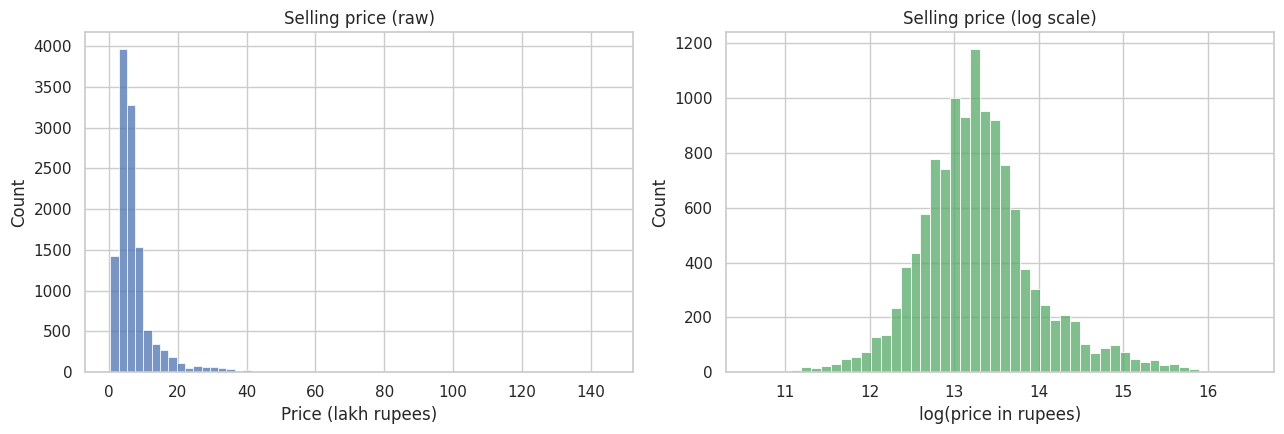

Skewness of raw price: 4.78
Skewness of log price: 0.54


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: raw price
sns.histplot(train["price_lakh"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Selling price (raw)")
axes[0].set_xlabel("Price (lakh rupees)")

# Right: log of the price
sns.histplot(train["log_price"], bins=50, ax=axes[1], color="#55A868")
axes[1].set_title("Selling price (log scale)")
axes[1].set_xlabel("log(price in rupees)")

save_fig("01_price_distribution")

# Skewness: 0 means symmetric. Larger numbers mean a longer tail on the right.
print("Skewness of raw price:", round(train["selling_price"].skew(), 2))
print("Skewness of log price:", round(train["log_price"].skew(), 2))

## 5. Price and vehicle age

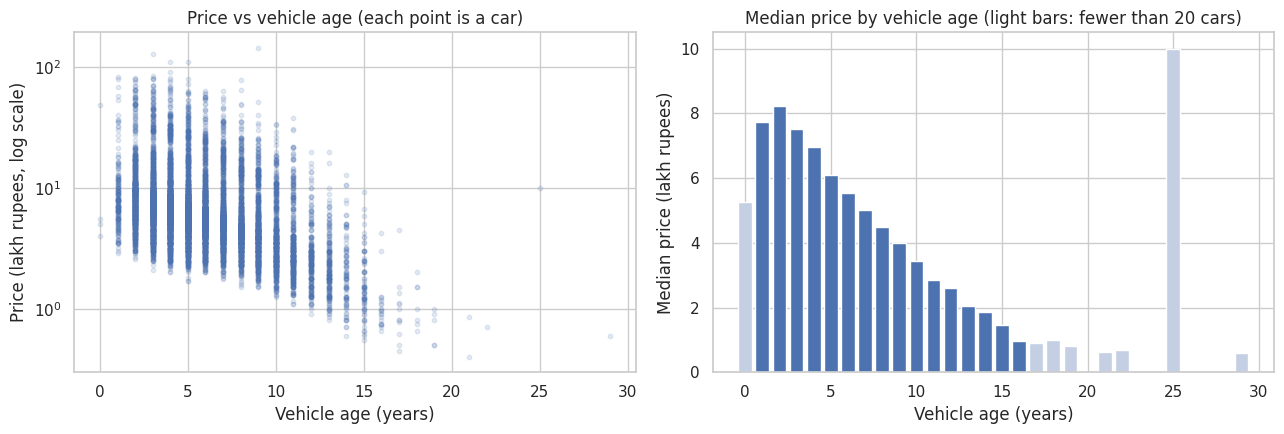

vehicle_age,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,21,22,25,29
median,5.25,7.72,8.22,7.5,6.95,6.1,5.55,5.0,4.5,4.0,...,1.85,1.46,0.95,0.9,1.0,0.8,0.62,0.7,10.0,0.6
count,4.00,180.00,919.00,1516.0,1778.00,1675.0,1517.00,1133.0,1027.0,805.0,...,95.00,76.00,22.00,12.0,7.0,5.0,2.00,1.0,1.0,1.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: every car as a point. The price axis is on a log scale so cheap and
# expensive cars are both visible.
axes[0].scatter(train["vehicle_age"], train["price_lakh"], alpha=0.15, s=10, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Price vs vehicle age (each point is a car)")
axes[0].set_xlabel("Vehicle age (years)")
axes[0].set_ylabel("Price (lakh rupees, log scale)")

# Right: median price at each age, which shows the trend clearly.
# Ages with very few cars are shown in a lighter color because they are not reliable.
by_age = train.groupby("vehicle_age")["price_lakh"].agg(["median", "count"])
colors = ["#4C72B0" if n >= 20 else "#C4CFE3" for n in by_age["count"]]
axes[1].bar(by_age.index, by_age["median"], color=colors)
axes[1].set_title("Median price by vehicle age (light bars: fewer than 20 cars)")
axes[1].set_xlabel("Vehicle age (years)")
axes[1].set_ylabel("Median price (lakh rupees)")

save_fig("02_price_vs_age")

by_age.round(2).T

## 6. Price and kilometers driven

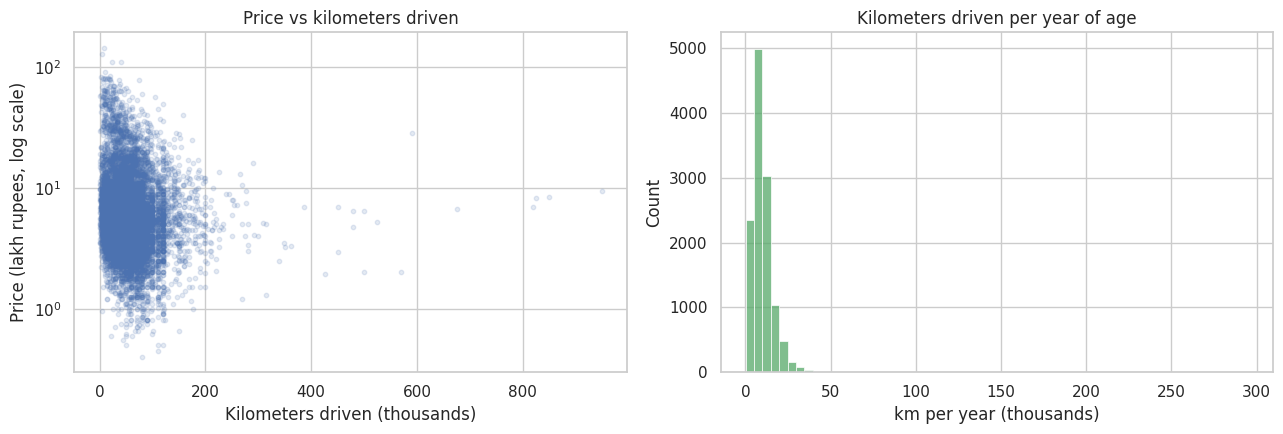

Cars with more than 50,000 km per year:  19
Cars with more than 100,000 km per year: 9


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: price against total kilometers driven
axes[0].scatter(train["km_driven"] / 1000, train["price_lakh"], alpha=0.15, s=10, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Price vs kilometers driven")
axes[0].set_xlabel("Kilometers driven (thousands)")
axes[0].set_ylabel("Price (lakh rupees, log scale)")

# Right: the new feature km_per_year, to check it is sensible
sns.histplot(train["km_per_year"] / 1000, bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("Kilometers driven per year of age")
axes[1].set_xlabel("km per year (thousands)")

save_fig("03_price_vs_km")

# How many cars have an unrealistic number of kilometers per year?
print("Cars with more than 50,000 km per year: ", (train["km_per_year"] > 50_000).sum())
print("Cars with more than 100,000 km per year:", (train["km_per_year"] > 100_000).sum())

## 7. Price, engine size, and power

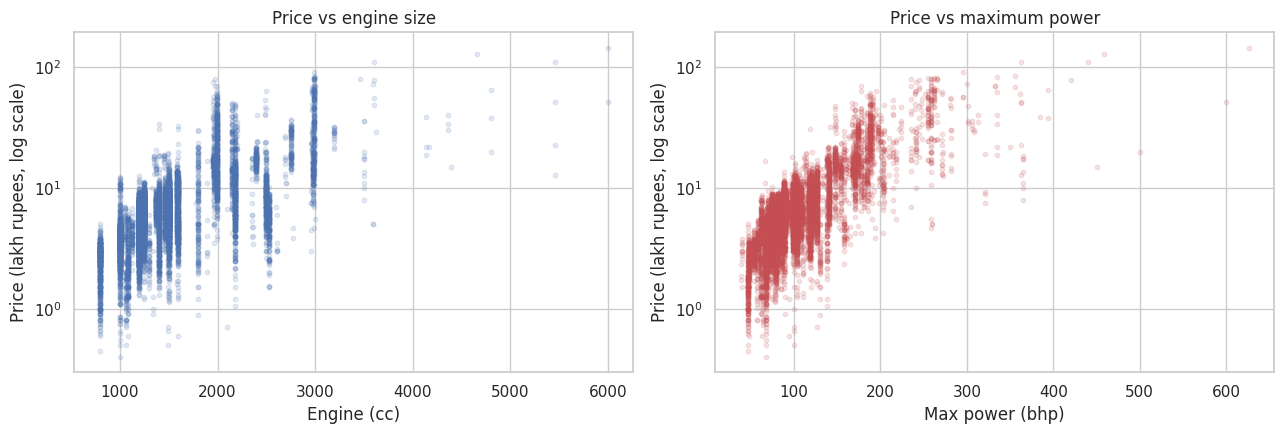

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Engine size (cc) against price
axes[0].scatter(train["engine"], train["price_lakh"], alpha=0.15, s=10, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Price vs engine size")
axes[0].set_xlabel("Engine (cc)")
axes[0].set_ylabel("Price (lakh rupees, log scale)")

# Maximum power (bhp) against price
axes[1].scatter(train["max_power"], train["price_lakh"], alpha=0.15, s=10, color="#C44E52")
axes[1].set_yscale("log")
axes[1].set_title("Price vs maximum power")
axes[1].set_xlabel("Max power (bhp)")
axes[1].set_ylabel("Price (lakh rupees, log scale)")

save_fig("04_price_vs_engine_power")

## 8. Price by fuel type, transmission, and seller type

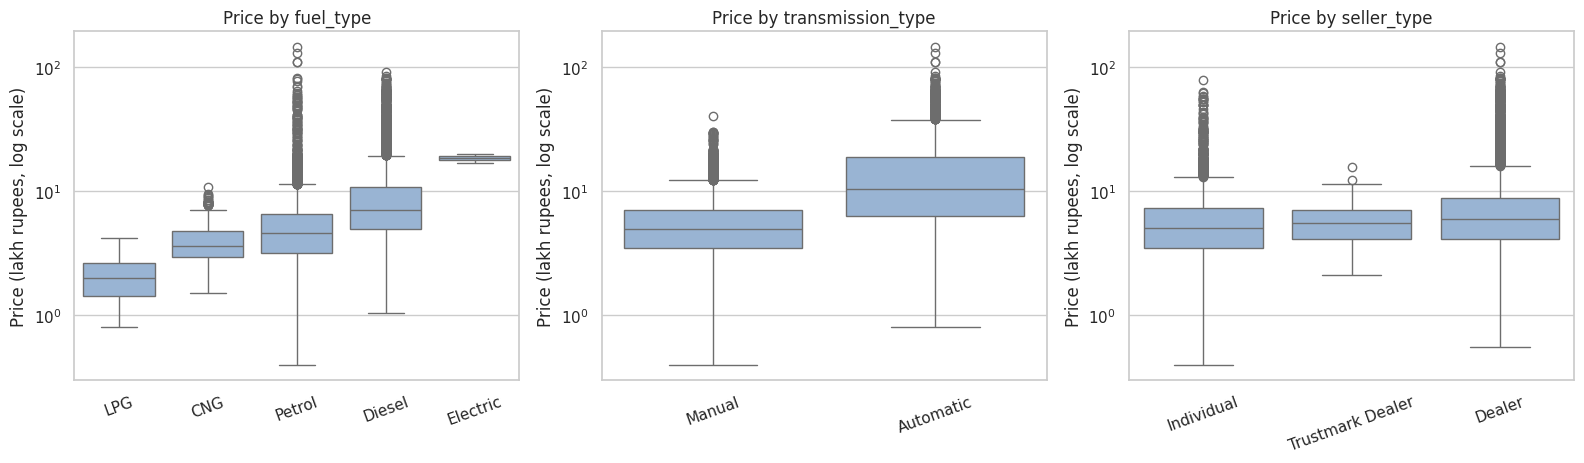

           count  median
fuel_type               
LPG           35    2.00
CNG          235    3.65
Petrol      6075    4.60
Diesel      5844    7.00
Electric       3   18.65

                   count  median
transmission_type               
Manual              9641     5.0
Automatic           2551    10.5

                  count  median
seller_type                    
Individual         4458    5.10
Trustmark Dealer    150    5.52
Dealer             7584    5.95



In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, col in zip(axes, ["fuel_type", "transmission_type", "seller_type"]):
    # Order the groups from the lowest to the highest median price
    order = train.groupby(col)["price_lakh"].median().sort_values().index
    sns.boxplot(data=train, x=col, y="price_lakh", order=order, ax=ax, color="#8FB4DD")
    ax.set_yscale("log")
    ax.set_title(f"Price by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Price (lakh rupees, log scale)")
    ax.tick_params(axis="x", rotation=20)

save_fig("05_price_by_category")

# The number of cars and the median price in each group
for col in ["fuel_type", "transmission_type", "seller_type"]:
    print(train.groupby(col)["price_lakh"].agg(["count", "median"]).round(2)
               .sort_values("median").to_string())
    print()

## 9. Price by brand

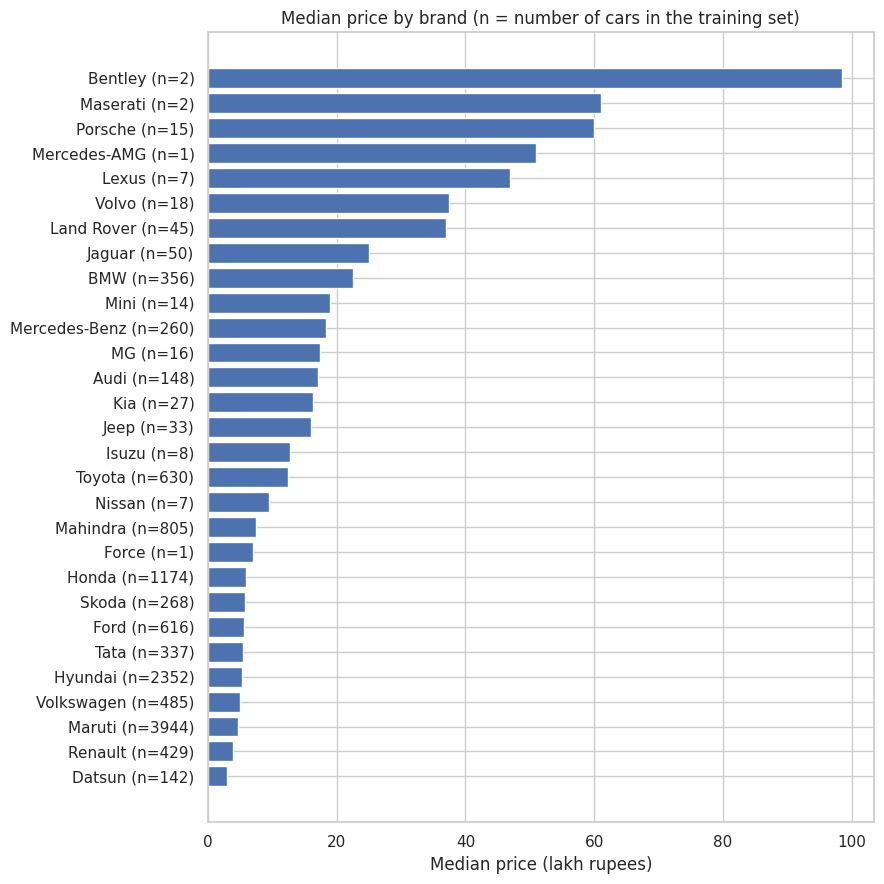

Brands with fewer than 10 cars: 7 of 29


In [11]:
# Median price and number of cars for every brand
by_brand = train.groupby("brand")["price_lakh"].agg(["median", "count"]).sort_values("median")

# Put the number of cars in each label, because some brands have only a few cars
labels = [f"{brand} (n={n})" for brand, n in zip(by_brand.index, by_brand["count"])]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(labels, by_brand["median"], color="#4C72B0")
ax.set_xlabel("Median price (lakh rupees)")
ax.set_title("Median price by brand (n = number of cars in the training set)")

save_fig("06_price_by_brand")

print("Brands with fewer than 10 cars:", (by_brand["count"] < 10).sum(), "of", len(by_brand))

## 10. Correlations

The correlation shows how strongly two numeric columns move together: +1 means they rise together, -1 means one rises as the other falls, and 0 means no straight-line relationship. Because the price is skewed, we include the log of the price as well.

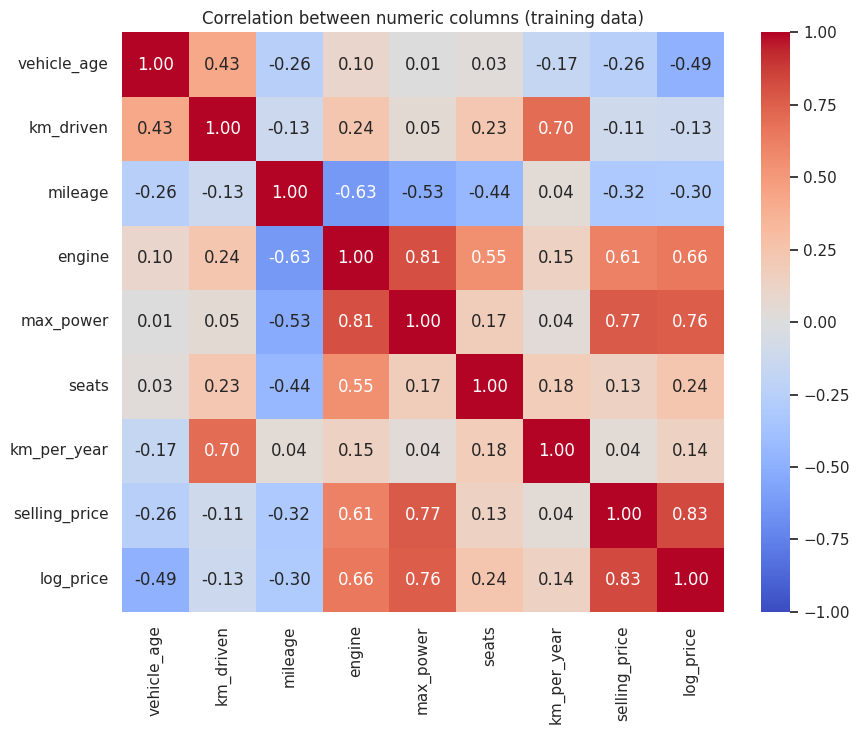

             selling_price  log_price
max_power             0.77       0.76
engine                0.61       0.66
vehicle_age          -0.26      -0.49
mileage              -0.32      -0.30
seats                 0.13       0.24
km_per_year           0.04       0.14
km_driven            -0.11      -0.13


In [12]:
corr_cols = numeric_features + ["selling_price", "log_price"]
corr = train[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric columns (training data)")

save_fig("07_correlation_heatmap")

# Correlation of every feature with the price, strongest first
print(corr[["selling_price", "log_price"]]
        .drop(["selling_price", "log_price"])
        .sort_values("log_price", key=abs, ascending=False)
        .round(2))

## 11. Key findings

All numbers below come from the training set.

**Price distribution**
- The raw price is strongly right-skewed (skewness about 4.8): the middle half of cars cost between about 4 and 8 lakh, with a long tail of expensive cars up to 145 lakh. Taking the log makes it much more regular (skewness about 0.5). This supports comparing raw price against log price when modeling in Part 5.

**Vehicle age**
- Median price falls steadily with age, from about 8 lakh at 2 years to about 3.4 lakh at 10 years and about 1.5 lakh at 15 years. Age has a clearer relationship with log price (correlation about -0.49) than with raw price (about -0.26).
- Very few cars are older than 15 years, so the pattern at those ages is not reliable. Two cars (ages 25 and 29) are rare outliers.

**Kilometers driven**
- Total kilometers have only a weak relationship with price (correlation about -0.11 to -0.13). Age and kilometers are themselves related (about 0.43), so part of kilometers' effect is already captured by age.
- Some rows have unrealistic usage. 9 training-set cars show more than 100,000 km per year (for example a 2-year-old Toyota Fortuner with 590,000 km). They passed the 1,000,000 km cleaning rule, which was lenient. They are very few, but this is worth a decision later.

**Engine and power**
- Maximum power (about 0.77) and engine size (about 0.61 to 0.66) are the strongest numeric signals of price, much stronger than age or kilometers. This is also why the app should auto-fill them from the chosen model.
- Engine and power are strongly related to each other (about 0.81), and mileage falls as engine size rises (about -0.63). Using all of them together will add some overlapping information, which we examine in Part 4.

**Fuel type, transmission, and seller type**
- Diesel cars are priced higher than petrol cars (median about 7.0 vs 4.6 lakh). CNG and LPG cars are cheaper. There are only 3 electric cars, so no conclusion can be drawn about them.
- Automatic cars are priced much higher than manual (median about 10.5 vs 5.0 lakh), partly because automatics are more common among larger and luxury cars.
- Differences between seller types are small compared with the other factors (median about 5.1 lakh for individuals vs about 6.0 lakh for dealers).

**Brand**
- Brand is a strong signal: median price ranges from about 3 lakh (Datsun) to about 98 lakh (Bentley). Some brands have very few cars (Bentley 2, Maserati 2, Mercedes-AMG 1), so their medians are not reliable and the model will have little to learn from for them.

**What this means for the next steps**
- Use log price as a modeling option (Part 5).
- Engine, max power, and brand are likely the most useful features. Part 4 will confirm this with feature importance.
- Overlapping features (engine, power, mileage) and the unrealistic km-per-year rows should be looked at in Part 4.

## 12. Save the charts

In [13]:
# Zip the saved charts so they can be downloaded and put into reports/figures/ in the repo
import shutil

shutil.make_archive("eda_figures", "zip", "figures")
print("Charts saved:", sorted(os.listdir("figures")))

try:
    from google.colab import files
    files.download("eda_figures.zip")
except ImportError:
    print("Not running in Colab, so the zip file stays in the current folder.")


Charts saved: ['01_price_distribution.png', '02_price_vs_age.png', '03_price_vs_km.png', '04_price_vs_engine_power.png', '05_price_by_category.png', '06_price_by_brand.png', '07_correlation_heatmap.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>